# **informações e importaçao do dataset**

Conhecendo as colunas do dataset

O dataset contém informações sobre imóveis disponíveis para aluguel em São Paulo.

address: endereço do imóvel.

district: distrito ou região onde o imóvel está localizado.

area: área do imóvel, em metros quadrados (m²).

bedrooms: quantidade de quartos.

garage: quantidade de vagas de garagem.

type: tipo de imóvel, como (apartamento, casa etc.)

rent: valor anunciado do aluguel.

total: O custo total do imóvel, incluindo aluguel, impostos e outras taxas.

importei a biblioteca panda

In [1]:
#Importei o panda
import pandas as pd


# **Esses passos faz parte da preparaçao dos dados.**

1. colequei pra pra a leitura do dataframe ser a variavel dados.

In [2]:
#Coleiquei a variavel "dados" o dataframe
dados = pd.read_csv("data.csv")

2. fiz o teste pra ver se o dataframe esta funcionando corretamente

In [3]:
#Teste das 5 linhas e as fileiras do data frame
dados.head()

,address,district,area,bedrooms,garage,type,rent,total
0,Rua Herval,Belenzinho,21,1,0,Studio e kitnet,2400,2939
1,Avenida São Miguel,Vila Marieta,15,1,1,Studio e kitnet,1030,1345
2,Rua Oscar Freire,Pinheiros,18,1,0,Apartamento,4000,4661
3,Rua Júlio Sayago,Vila Ré,56,2,2,Casa em condomínio,1750,1954
4,Rua Barata Ribeiro,Bela Vista,19,1,0,Studio e kitnet,4000,4654


3. preciso enterder o tamanho do dataframe que estou operando quantidade de linhas e colunas

In [4]:
#Quantas linhas e colunas tem o dataframe
dados.shape

(11657, 8)

4. procurando inconsistencias na dataframe como letra onde deveria ser numero e vise versa


In [5]:
#Vendo se tem letras e numeros na coluna onde nao deveria estar
dados.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11657 entries, 0 to 11656
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   address   11657 non-null  object
 1   district  11657 non-null  object
 2   area      11657 non-null  int64 
 3   bedrooms  11657 non-null  int64 
 4   garage    11657 non-null  int64 
 5   type      11657 non-null  object
 6   rent      11657 non-null  int64 
 7   total     11657 non-null  int64 
dtypes: int64(5), object(3)
memory usage: 728.7+ KB


5. testando se tem colunas nao prenchidas nas colunas

In [6]:
#Teste de espaço vazio nas colunas
dados.isnull().sum()

,0
address,0
district,0
area,0
bedrooms,0
garage,0
type,0
rent,0
total,0


6. verificando se tem dados duplicados exemplo o mesmo o imovel repedito

In [7]:
#Teste de duplicaçao de informaçoes
dados.duplicated().sum()

np.int64(0)

7. vendo o valor maximo minino pra ver valores que estao fora do normal e tambem o valor medio

In [8]:
#Vendo a media, min, e max e valores incorretos
dados.describe()

,area,bedrooms,garage,rent,total
count,11657.000000,11657.000000,11657.000000,11657.000000,11657.000000
mean,84.655658,1.966286,1.060393,3250.814789,4080.030625
std,74.020536,0.931313,1.132349,2650.711557,3352.480274
min,0.000000,0.000000,0.000000,500.000000,509.000000
25%,40.000000,1.000000,0.000000,1590.000000,1996.000000
50%,60.000000,2.000000,1.000000,2415.000000,3057.000000
75%,96.000000,3.000000,2.000000,3800.000000,4774.000000
max,580.000000,6.000000,6.000000,25000.000000,28700.000000


8. testando pra ver se tem imoveis com valores invalidos no metro quadrado

In [9]:
#Teste pra ver quantos imoveis com m²=0
(dados["area"] == 0).sum()

np.int64(2)

9. tinha aparecido 2 imoveis usei o comando pra ver quais esses dois imoveis sao pra ter certeza antes de tirar ele

In [10]:
#Linhas com valor da "m²" errado
dados[dados["area"] == 0]

,address,district,area,bedrooms,garage,type,rent,total
2983,Rua Relíquia,Jardim das Laranjeiras,0,2,1,Apartamento,1600,2569
7085,Rua Edmundo de Amicis,Morumbi,0,3,2,Casa,3200,3351


10. criei uma variavel nova usei a variavel pra os imoveis que eu avaliar que nao seja inconstante e tambem nao perder as informaçoes original do dataframe

In [11]:
#criando uma variavel sem essas duas linhas com a metragem errada
dados_limpos = dados[dados["area"] != 0].copy()

11. olhando os tipos de imoveis que tem pra tem uma base sobre os imoveis e poder encontrar os imoveis incostantes

In [12]:
#vendo os tipos de imoveis que tem
dados_limpos["type"].unique()

array(['Studio e kitnet', 'Apartamento', 'Casa em condomínio', 'Casa'],
      dtype=object)

12. vendo a quantidade imoveis que nao tem quartos pra encontrar inconsistencias

In [13]:
#vendo quantos tipos de imoveis tem 0 quartos
dados_limpos.groupby("type")["bedrooms"].apply(lambda x: (x == 0).sum())

,bedrooms
type,
Apartamento,7
Casa,4
Casa em condomínio,0
Studio e kitnet,26


13. achei inconstante alguns imoveis nao ter quarto sem ser a kitnet ou studio ai quis ver eles detalhadamente

In [14]:
#vendo os apartamento e casa com 0 quartos
dados_limpos[
    (dados_limpos["bedrooms"] == 0) &
    (dados_limpos["type"].isin(["Apartamento", "Casa"]))]

,address,district,area,bedrooms,garage,type,rent,total
476,Rua Doutor Miguel Vieira Ferreira,Tatuapé,30,0,0,Apartamento,1840,2113
1002,Rua Natividade Saldanha,São Lucas,28,0,0,Apartamento,1100,1391
1416,Rua Natividade Saldanha,São Lucas,27,0,0,Apartamento,1100,1387
1552,Rua Natividade Saldanha,São Lucas,40,0,0,Apartamento,1300,1706
1595,Rua Natividade Saldanha,São Lucas,45,0,0,Apartamento,1400,1855
1596,Rua Marilândia,Freguesia do Ó,70,0,0,Casa,3100,3152
1925,Rua Santa Lúcia,Cidade Mãe do Céu,22,0,0,Apartamento,1000,1263
9501,Rua Dom Armando Lombardi,Vila Progredior,250,0,3,Casa,10000,10290
9674,Rua Adalberto Kemeny,Parque Industrial Tomas Edson,47,0,1,Apartamento,2330,3190
10062,Rua Graúna,Vila Uberabinha,141,0,0,Casa,7000,7208


14. e encontrei os valores das linhas "1596", "9501", "10082", "10062" muito incostante por que sao metragem altas e nao tem quartos eu achei muito inconstante esse valor e opitei por nao deixar esses imoveis

In [15]:
#removendo as linhas incostantes com zero quartos
dados_limpos = dados_limpos.drop([1596, 9501, 10082, 10062])

15. fiz um teste rapido pra ver se os imoveis foram realmente removidos da variavel "dados_limpos"

In [16]:
#vendo  se realmente elas foram removidas
dados_limpos[
    (dados_limpos["bedrooms"] == 0) &
    (dados_limpos["type"].isin(["Apartamento", "Casa"]))]

,address,district,area,bedrooms,garage,type,rent,total
476,Rua Doutor Miguel Vieira Ferreira,Tatuapé,30,0,0,Apartamento,1840,2113
1002,Rua Natividade Saldanha,São Lucas,28,0,0,Apartamento,1100,1391
1416,Rua Natividade Saldanha,São Lucas,27,0,0,Apartamento,1100,1387
1552,Rua Natividade Saldanha,São Lucas,40,0,0,Apartamento,1300,1706
1595,Rua Natividade Saldanha,São Lucas,45,0,0,Apartamento,1400,1855
1925,Rua Santa Lúcia,Cidade Mãe do Céu,22,0,0,Apartamento,1000,1263
9674,Rua Adalberto Kemeny,Parque Industrial Tomas Edson,47,0,1,Apartamento,2330,3190


16. vendo se tem algum linha que o valor do aluguel é mais caro que o valor todo do aluguel mais taxas porque seriam valores inconstantes

In [17]:
#testando pra ver se tem algum rent maior que o total na mesma linha
(dados_limpos["rent"] >= dados_limpos["total"]).sum()

np.int64(0)

17. vendo se alguma kitnet ou estudio tem valores muito altos pra ser somente uma kitnet e um studio

In [18]:
#vendos quantas kitnets e studio que tem >=70m²
studios_mais_quartos = dados_limpos[
    (dados_limpos["type"] == "Studio e kitnet") &
    (dados_limpos["area"] >= 70)
]

print("Quantidade:", len(studios_mais_quartos))
studios_mais_quartos

Quantidade: 9


,address,district,area,bedrooms,garage,type,rent,total
848,Alameda Tietê,Cerqueira César,82,1,2,Studio e kitnet,8500,10720
2727,Rua Santo Antônio,Bela Vista,80,2,1,Studio e kitnet,4500,6284
6221,Domingos Lopes da Silva,Vila Suzana,74,1,1,Studio e kitnet,1649,2474
6711,Rua Antônio Pinto do Rêgo Freitas,Jardim Boa Vista (zona Oeste),130,6,3,Studio e kitnet,3000,3200
7125,Rua Oliveira Catrambi,Jardim Vila Formosa,77,2,1,Studio e kitnet,6000,6577
7132,Rua Oliveira Catrambi,Jardim Vila Formosa,76,2,1,Studio e kitnet,6000,6577
8821,Rua Amapá Grande,Vila Canero,92,1,0,Studio e kitnet,1350,1402
9346,Rua Samia Haddad,Vila Suzana,86,1,2,Studio e kitnet,5250,7032
10386,Rua Senador César Lacerda Vergueiro,Sumarezinho,70,1,1,Studio e kitnet,15000,16680


18. achei algumas kitnets e studios com valores exagerados de metro quadrado e tirei da variavel "dados_limpos"

In [19]:
#kitnets e studio que for >= 70 de area tirar da lista, numero exagerado
dados_limpos = dados_limpos[
    ~(
        (dados_limpos["type"] == "Studio e kitnet") &
        (dados_limpos["area"] >= 70)
    )
]

19. vendo se Studio e kitnet tem quartos caso tenha sao imoveis incorretos porque deixa de ser Studio e kitnet e se torna um quarto e sala e nao Studio e kitnet

In [20]:
#vendo quantos quartos os "Studio e kitnet" tem
(
    (dados_limpos["type"] == "Studio e kitnet") &
    (dados_limpos["bedrooms"] > 0)
).sum()

np.int64(1346)

20. removi os Studio e kitnet com quartos da variavel "dados_limpos"

In [21]:
#tirando Studio e kitnet com quartos
dados_limpos = dados_limpos[
    ~(
        (dados_limpos["type"] == "Studio e kitnet") &
        (dados_limpos["bedrooms"] > 0)
    )
]

21. procurando numeros incorretos de com uso de virgula em dados que nao pode ter numeros com virgula

In [22]:
#vendo se tem numeros com virgulas em "area", "bedrooms", "garage"
dados_limpos[["area", "bedrooms", "garage"]].apply(
    lambda coluna: (coluna % 1 != 0).sum()
)

,0
area,0
bedrooms,0
garage,0


22. procurando imoveis com metragem muito baixas pra ver ser encontro valores muito inconstantes que saiam da realidade

In [23]:
#olhando imoveis com metragem muito baixa
dados_limpos[
    (dados_limpos["type"].isin(["Casa", "Apartamento","Casa em condomínio" ])) &
    (dados_limpos["area"] < 10)
]

,address,district,area,bedrooms,garage,type,rent,total
1223,Rua Mussumés,Vila Maria Alta,5,1,0,Casa,570,594
5323,Rua Solidônio Leite,Vila Ivone,2,2,2,Casa,2500,2711
9898,Rua Visconde de Porto Seguro,Jardim dos Estados,1,4,3,Casa em condomínio,8500,11420
11055,Travessa Santa Filomena,Vila Campo Grande,4,1,0,Casa,630,641


23. removi as linhas "5323" "9898" valores inconstantes demais pra metragem que tinha

In [24]:
dados_limpos = dados_limpos.drop([5323, 9898])

24. analisando se tem imoveis muito caros com metragem extremamente baixas tornando e vise e versa tornando um imovel inconstante e estranho ultilisei uma tecnica bem simples o valor do aluguel dividido pela metragem e coloquei uma regra pra aparecer somente os exagerados

In [25]:
#analisando os imoveis muito caros com metragem estranhas
dados_limpos[
    (dados_limpos["rent"] / dados_limpos["area"] >= 500)
]

,address,district,area,bedrooms,garage,type,rent,total
4849,Rua Doutor Alvares Teixeira,Jardim Tango,15,1,1,Casa,15000,15640
8215,Rua Cândido Lacerda,Vila Regente Feijó,12,1,2,Apartamento,9136,9499


25. removi essas duas linhas da variavel dados_limpos porque o imovel estremamente caro pra o metro quadrado pouco com valores inconstate demais pra ser realmente um imovel valido

In [26]:
#removendo linhas "4849", "8215" da variavel "dados_limpos"
dados_limpos = dados_limpos.drop([4849, 8215])

In [27]:
dados_removidos = dados.loc[~dados.index.isin(dados_limpos.index)].copy()

print("Quantidade de registros removidos:", len(dados_removidos))

dados_removidos

Quantidade de registros removidos: 1365


,address,district,area,bedrooms,garage,type,rent,total
0,Rua Herval,Belenzinho,21,1,0,Studio e kitnet,2400,2939
1,Avenida São Miguel,Vila Marieta,15,1,1,Studio e kitnet,1030,1345
4,Rua Barata Ribeiro,Bela Vista,19,1,0,Studio e kitnet,4000,4654
7,Avenida Cásper Líbero,Centro,26,1,0,Studio e kitnet,1727,2244
12,Rua Henrique Sertório,Tatuapé,32,1,0,Studio e kitnet,2100,2598
...,...,...,...,...,...,...,...,...
11554,Avenida Cauaxi,Alphaville Industrial,38,1,1,Studio e kitnet,3800,3947
11558,Alameda Mamoré,Alphaville Industrial,40,1,1,Studio e kitnet,3200,4182
11575,Avenida Marcos Penteado de Ulhôa Rodrigues,Tamboré,50,1,1,Studio e kitnet,3500,4610
11580,Avenida Marcos Penteado de Ulhôa Rodrigues,Tamboré,51,1,1,Studio e kitnet,6300,7406


 **Informações sobre a preparaçao dos dados**

Durante a análise dos dados, encontrei alguns imóveis com características que poderiam atrapalhar os resultados. Por isso, decidi remover alguns registros que achei suspeitos.

Imóveis com área igual a zero. Removi porque não faz sentido calcular o preço por metro quadrado de um imóvel sem área informada.

Casas com zero quartos. Retirei esses registros porque achei estranho ver casas com áreas grandes e nenhum quarto informado. Isso pode mostrar algum erro no preenchimento dos dados.

Removi studios e kitnets com área igual ou maior que 70 m². Achei que a metragem era muito alta para esse tipo de imóvel. Considerei que eles poderiam estar classificados de forma errada.

Studios e kitnets com um ou mais quartos. Também tirei esses registros porque essas características não seguem o padrão que eu esperava para esse tipo de imóvel, Studios e kitnets que tem quarto separado é considerado quarto e sala.

E tambem removi 2 registros que tinha um valor muito alto, pra um metro quadrado do imovel ridiculamente pequena.

Tambem criei uma nova variavel a "dados_removidos"pra armazenar os registros que removi da variavel "dados_limpos"

A ideia da limpeza foi evitar que registros possivelmente inconsistentes atrapalhassem a análise dos aluguéis. Mesmo assim, sei que algumas dessas características podem existir de verdade. Essas remoções seguiram os critérios que escolhi para o trabalho. Isso não quer dizer que todos os imóveis estavam cadastrados de forma errada.

# **Medias e Mediana**

muito importante calcular a mediana junto da media porque a media pode mudar muito o valor se tiver algum imovel extremamente caro que atrapalhe no resutado final ja a mediana é um ou dois imoveis que estiverem no centro da ordem do mais barato ao mais caro

In [28]:
#calculando media e mediana
media_aluguel = dados_limpos["rent"].mean()
mediana_aluguel = dados_limpos["rent"].median()

print("Média do aluguel: R$", round(media_aluguel, 2))
print("Mediana do aluguel: R$", round(mediana_aluguel, 2))

Média do aluguel: R$ 3393.29
Mediana do aluguel: R$ 2500.0


In [29]:
#
resumo_distritos = dados_limpos.groupby("district").agg(
    quantidade=("rent", "count"),
    aluguel_medio=("rent", "mean"))

distritos_validos = resumo_distritos[
    resumo_distritos["quantidade"] >= 30]

distritos_validos = distritos_validos.sort_values(
    "aluguel_medio",
    ascending=False)

distritos_validos.round(2)

,quantidade,aluguel_medio
district,,
Jardim Leonor,37,7414.00
Cerqueira César,125,7096.02
Paraíso,77,6715.13
Jardim Paulista,197,6651.77
Vila Nova Conceição,70,6461.09
...,...,...
Liberdade,89,1949.52
Vila Ema,34,1767.32
Campos Elíseos,80,1730.06


In [30]:
# 10 distritos com maior aluguel médio
distritos_validos.head(10)

,quantidade,aluguel_medio
district,,
Jardim Leonor,37,7414.000000
Cerqueira César,125,7096.016000
Paraíso,77,6715.129870
Jardim Paulista,197,6651.766497
Vila Nova Conceição,70,6461.085714
Brooklin Paulista,40,6455.875000
Cidade Monções,45,6327.733333
Itaim Bibi,43,6296.976744
Vila Madalena,30,6054.333333


In [31]:
# 10 distritos com menor aluguel médio
distritos_validos.tail(10).sort_values("aluguel_medio")

,quantidade,aluguel_medio
district,,
Taboão,48,1493.416667
Sé,46,1641.500000
Campos Elíseos,80,1730.062500
Vila Ema,34,1767.323529
Liberdade,89,1949.516854
Penha de França,39,1993.153846
Centro Histórico de São Paulo,43,2031.790698
Vila Alpina,37,2072.837838
Lauzane Paulista,36,2085.805556


# **Graficos**

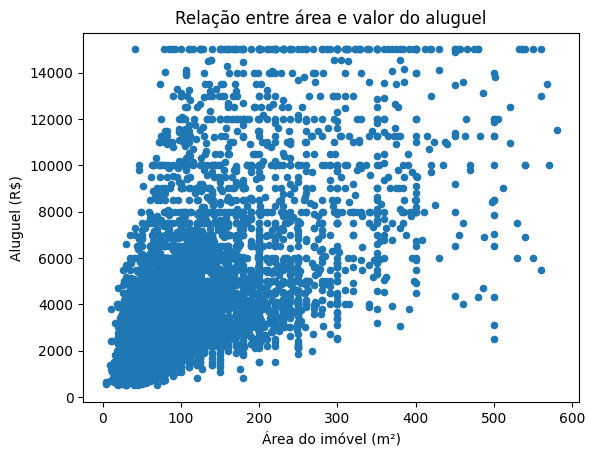

In [32]:
import matplotlib.pyplot as plt

dados_limpos.plot(
    kind="scatter",
    x="area",
    y="rent")

plt.title("Relação entre área e valor do aluguel")
plt.xlabel("Área do imóvel (m²)")
plt.ylabel("Aluguel (R$)")
plt.show()

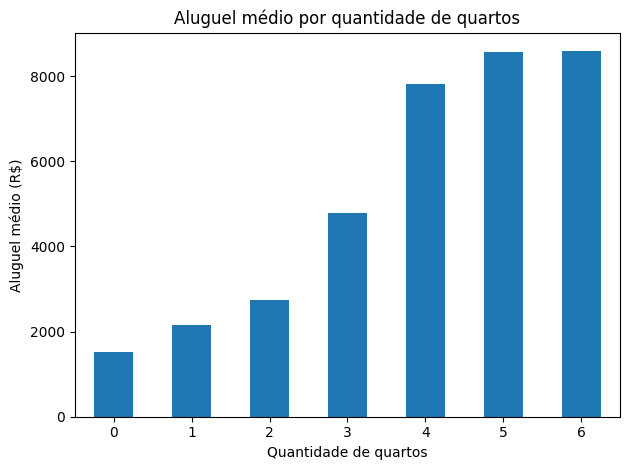

In [33]:
aluguel_quartos = dados_limpos.groupby("bedrooms")["rent"].mean()

aluguel_quartos.plot(kind="bar")

plt.title("Aluguel médio por quantidade de quartos")
plt.xlabel("Quantidade de quartos")
plt.ylabel("Aluguel médio (R$)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

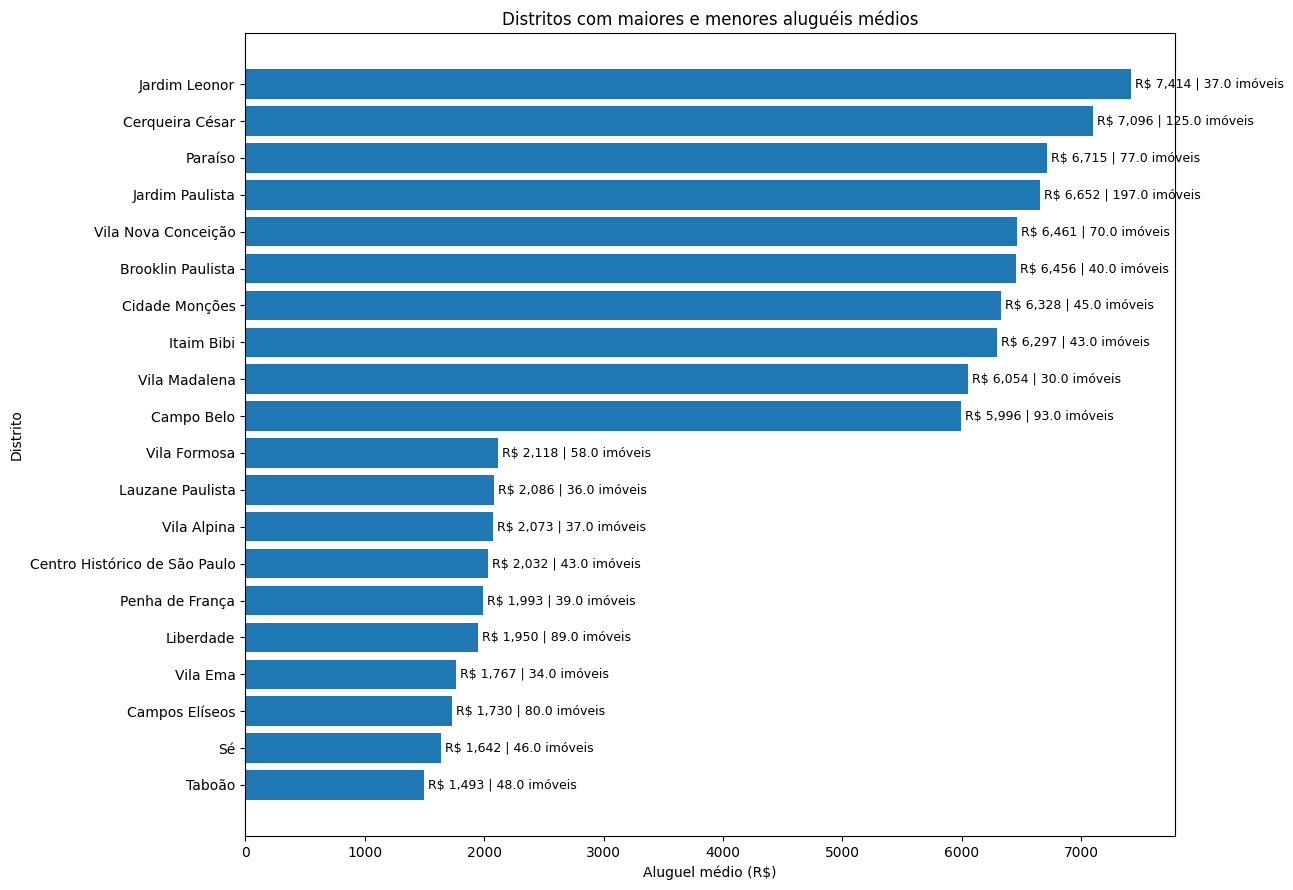

,Quantidade de imóveis,Aluguel médio (R$)
district,,
Taboão,48,1493.42
Sé,46,1641.50
Campos Elíseos,80,1730.06
Vila Ema,34,1767.32
Liberdade,89,1949.52
Penha de França,39,1993.15
Centro Histórico de São Paulo,43,2031.79
Vila Alpina,37,2072.84
Lauzane Paulista,36,2085.81


In [34]:
import pandas as pd
import matplotlib.pyplot as plt

# Calcular a quantidade de imóveis e o aluguel médio por distrito
resumo_distritos = dados_limpos.groupby("district").agg(
    quantidade=("rent", "count"),
    aluguel_medio=("rent", "mean"))

# Considerar somente distritos com 30 ou mais imóveis
distritos_validos = resumo_distritos[
    resumo_distritos["quantidade"] >= 30]

# Selecionar os 10 mais caros e os 10 mais baratos
mais_caros = distritos_validos.nlargest(10, "aluguel_medio")
mais_baratos = distritos_validos.nsmallest(10, "aluguel_medio")

# Juntar os resultados sem duplicar distritos
selecionados = pd.concat([mais_baratos, mais_caros])
selecionados = selecionados[~selecionados.index.duplicated(keep="first")]

# Ordenar pelo aluguel médio
selecionados = selecionados.sort_values("aluguel_medio")

# Criar o gráfico
plt.figure(figsize=(13, 9))

barras = plt.barh(
    selecionados.index,
    selecionados["aluguel_medio"])

# Mostrar aluguel médio e quantidade de imóveis
for barra, (_, linha) in zip(barras, selecionados.iterrows()):
    plt.text(
        barra.get_width(),
        barra.get_y() + barra.get_height() / 2,
        f' R$ {linha["aluguel_medio"]:,.0f} | {linha["quantidade"]} imóveis',
        va="center",
        fontsize=9)

plt.title("Distritos com maiores e menores aluguéis médios")
plt.xlabel("Aluguel médio (R$)")
plt.ylabel("Distrito")
plt.tight_layout()
plt.show()

# Exibir tabela com os valores exatos
tabela = selecionados.copy()
tabela["aluguel_medio"] = tabela["aluguel_medio"].round(2)
tabela = tabela.rename(columns={
    "quantidade": "Quantidade de imóveis",
    "aluguel_medio": "Aluguel médio (R$)"})

display(tabela)

# **Limitações da análise e cinco conclusões objetivas apoiadas nos resultados encontrados**

 **Limitações da análise**

**A análise tem algumas limitações, porque os dados não mostram tudo que pode influenciar o preço do aluguel, como a conservação do imóvel, e quanto tempo atra ele foi construido . Também tem distritos com mais anúncios que outros, o que pode acabar influenciando os resultados. Outro ponto é que o preço que aparece no anúncio pode ser diferente do valor que o proprietário aceita no final. Além disso, a retirada de alguns imóveis da análise também pode mudar os resultados, dependendo dos critérios que usei para limpar os dados.**

 **Diferença entre média e mediana:**

 o aluguel médio dos imóveis analisados foi de R$ 3.393,29, enquanto a mediana foi de R 2.500,00. essa diferença acontece porque quando calcula a media se tiver um imovel com o valor muito grande vai terminar puxando o valor da media pra cima.


 **Relação entre área e aluguel:**

 a correlação entre a área do imóvel e o valor do aluguel foi de aproximadamente 0,67. Isso indica uma relação positiva: imóveis com áreas maiores tendem a ter um aluguel mais caro, mesmo que isso não aconteça  em todos os casos.


 **Quantidade de quartos:**

 os imóveis com um quarto apresentaram aluguel médio de R$ 2.157,49, enquanto aqueles com três quartos tiveram média de R 4.795,90. Nos dados analisados, isso indica que imóveis com mais quartos o valor do imovel costuma ser mais caro.


 **Distrito com maior aluguel médio:**

 entre os distritos com no minimo 30 imóveis registrados, Jardim Leonor teve o maior aluguel médio, de R$ 7.414,00, considerando 37 registros. Esse resultado mostra que o distrito teve o maior valor médio entre os locais comparados.


 **Distrito com menor aluguel médio:**

 entre os distritos com no minimo 30 imóveis registrados, Taboão teve o menor aluguel médio, de R$ 1.493,42, considerando 48 registros. Isso mostra uma diferença grande entre os valores médios encontrados nos distritos que foi analizado.